In [1]:
import os, io, re, json, time, math, random, zipfile, itertools, warnings
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- configuration (edit freely) ----------------
N_QA_SCANS      = 400      # 3DSSG scans used for the retrieval benchmark (Part C); max 1335
QA_PER_TYPE     = 4        # questions generated per scan per question type
BACKGROUND      = {"floor", "ceiling"}   # removed as in Paper-1 ("background elements (e.g. floor, ceiling) are filtered out")
PAPER_DTHRESH   = 0.5      # Paper-1 Eq.19 distance threshold (metres)
PAPER_TOPK      = 3        # Paper-1 top-k chunks
# --------------------------------------------------------------

SEARCH_ROOTS = [r for r in ["/kaggle/input", os.environ.get("FYDP_DATA", "./data")] if os.path.isdir(r)]
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("./fydp_outputs")
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
C_PAPER, C_OURS, C_ALT, C_GREY = "#1f5aa6", "#e08a00", "#2a9d8f", "#9aa0a6"

def walk_files(name):
    hits = []
    for root in SEARCH_ROOTS:
        for dp, dn, fn in os.walk(root):
            dn[:] = [d for d in dn if not d.startswith(".")]
            if name in fn:
                hits.append(os.path.join(dp, name))
    return hits

OBJ_JSON = (walk_files("objects.json") or [None])[0]
REL_JSON = (walk_files("relationships.json") or [None])[0]
SEMSEG = {}
for p in walk_files("semseg.v2.json"):
    SEMSEG.setdefault(os.path.basename(os.path.dirname(p)), p)   # duplicates of the same scan are ignored
SCAN_DIRS = {sid: os.path.dirname(p) for sid, p in SEMSEG.items()}
PAIR_CSV = [p for p in walk_files("all_scene_pairs.csv") if "multi_scene_results" in p]
PAIR_CSV = PAIR_CSV[0] if PAIR_CSV else None

print("search roots   :", SEARCH_ROOTS)
print("objects.json   :", OBJ_JSON)
print("relationships  :", REL_JSON)
print("scans w/ geometry (semseg.v2.json):", len(SEMSEG))
for sid, d in SCAN_DIRS.items():
    has_seq = os.path.exists(os.path.join(d, "sequence.zip")) or os.path.isdir(os.path.join(d, "sequence"))
    has_ply = os.path.exists(os.path.join(d, "labels.instances.annotated.v2.ply"))
    print(f"   {sid}  RGB-D={'yes' if has_seq else 'no'}  instance-mesh={'yes' if has_ply else 'no'}")
print("output folder  :", OUT)
assert OBJ_JSON and REL_JSON, "Attach the dataset that contains 3DSSG objects.json and relationships.json"

search roots   : ['/kaggle/input']
objects.json   : /kaggle/input/datasets/rokiajannat/3dssgproject/3DSSG/objects.json
relationships  : /kaggle/input/datasets/rokiajannat/3dssgproject/3DSSG/relationships.json
scans w/ geometry (semseg.v2.json): 10
   7272e161-a01b-20f6-8b5a-0b97efeb6545  RGB-D=no  instance-mesh=no
   c7895f78-339c-2d13-82bb-cc990cbbc90f  RGB-D=no  instance-mesh=no
   baf0a8fb-26d4-2033-8a28-2001356bbb9a  RGB-D=no  instance-mesh=no
   422885e0-192d-25fc-844a-62e395291839  RGB-D=no  instance-mesh=no
   bf9a3dd3-45a5-2e80-8163-8a5b2573aca4  RGB-D=no  instance-mesh=no
   6a36053f-fa53-2915-9579-3938283bc154  RGB-D=no  instance-mesh=no
   6e67e550-1209-2cd0-8294-7cc2564cf82c  RGB-D=no  instance-mesh=no
   f62fd5fd-9a3f-2f44-883a-1e5cf819608e  RGB-D=no  instance-mesh=no
   4731977e-f9f7-2a1a-955d-8cdd12ec7337  RGB-D=no  instance-mesh=no
   ab835faa-54c6-29a1-9b55-1a5217fcba19  RGB-D=no  instance-mesh=no
output folder  : /kaggle/working


In [2]:
PRED_GROUP = {}
for p in ["supported by", "attached to", "standing on", "lying on", "hanging on", "connected to", "leaning against",
          "part of", "belonging to", "build in", "standing in", "cover", "lying in", "hanging in", "inside"]:
    PRED_GROUP[p] = "support_contact"
PRED_GROUP["close by"] = "proximity"
for p in ["left", "right", "front", "behind"]:
    PRED_GROUP[p] = "directional"
LOCAL_PREDS = set(PRED_GROUP)                    # predicates a spatial pair filter should recover
QA_PREDS = LOCAL_PREDS                           # predicates used to build reasoning chains

with open(OBJ_JSON) as f: _objs = json.load(f)["scans"]
with open(REL_JSON) as f: _rels = json.load(f)["scans"]
rel_map = {s["scan"]: s["relationships"] for s in _rels}

SCENES = {}          # scan_id -> dict(labels, attrs, edges)
for s in _objs:
    sid = s["scan"]
    if sid not in rel_map: continue
    labels = {int(o["id"]): o["label"].strip().lower() for o in s["objects"]}
    attrs  = {int(o["id"]): o.get("attributes", {}) for o in s["objects"]}
    edges = sorted({(int(a), int(b), p.strip().lower()) for a, b, _, p in rel_map[sid]
                    if int(a) in labels and int(b) in labels and int(a) != int(b)})
    SCENES[sid] = dict(labels=labels, attrs=attrs, edges=edges)

n_obj = [len(v["labels"]) for v in SCENES.values()]
n_edge = [len(v["edges"]) for v in SCENES.values()]
print(f"scans with graphs: {len(SCENES)} | objects/scan: {np.mean(n_obj):.1f} | edges/scan: {np.mean(n_edge):.1f}")
pc = Counter(p for v in SCENES.values() for _, _, p in v["edges"])
print("most frequent local predicates:", [(p, c) for p, c in pc.most_common() if p in LOCAL_PREDS][:10])

scans with graphs: 1335 | objects/scan: 29.2 | edges/scan: 407.5
most frequent local predicates: [('right', 45357), ('left', 45357), ('close by', 26500), ('front', 24165), ('behind', 24165), ('attached to', 12761), ('standing on', 12672), ('lying on', 3571), ('hanging on', 2423), ('supported by', 1498)]


In [3]:
def box_from_semseg(g):
    ob = g["obb"]
    A = np.array(ob["normalizedAxes"], float).reshape(3, 3)       # rows = axes
    return make_box(np.array(ob["centroid"], float), A, np.array(ob["axesLengths"], float))

def make_box(c, A, L):
    k = int(np.argmax(np.abs(A[:, 2])))                             # vertical axis
    h = [i for i in range(3) if i != k]
    a1, a2 = A[h[0], :2], A[h[1], :2]
    a1 = a1 / (np.linalg.norm(a1) + 1e-12); a2 = a2 / (np.linalg.norm(a2) + 1e-12)
    e1, e2 = L[h[0]] / 2, L[h[1]] / 2
    cx = c[:2]
    poly = np.array([cx + e1*a1 + e2*a2, cx - e1*a1 + e2*a2, cx - e1*a1 - e2*a2, cx + e1*a1 - e2*a2])
    if poly_area_signed(poly) < 0: poly = poly[::-1]
    H = L[k]
    return dict(c=c, A=A, L=L, poly=poly, zmin=c[2]-H/2, zmax=c[2]+H/2, area=abs(poly_area_signed(poly)),
                vol=float(np.prod(L)), s=0.5*float(np.linalg.norm(L)))

def poly_area_signed(P):
    x, y = P[:, 0], P[:, 1]
    return 0.5 * float(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

def clip_poly(subject, clip):                                        # Sutherland–Hodgman, both convex CCW
    out = list(subject)
    for i in range(len(clip)):
        A, B = clip[i], clip[(i+1) % len(clip)]
        inp, out = out, []
        if not inp: break
        def inside(P): return (B[0]-A[0])*(P[1]-A[1]) - (B[1]-A[1])*(P[0]-A[0]) >= -1e-12
        def inter(P, Q):
            d1 = np.array(Q) - np.array(P); d2 = B - A
            den = d1[0]*d2[1] - d1[1]*d2[0]
            if abs(den) < 1e-15: return P
            t = ((A[0]-P[0])*d2[1] - (A[1]-P[1])*d2[0]) / den
            return np.array(P) + t*d1
        S = inp[-1]
        for E in inp:
            if inside(E):
                if not inside(S): out.append(inter(S, E))
                out.append(E)
            elif inside(S):
                out.append(inter(S, E))
            S = E
    return np.array(out) if len(out) >= 3 else None

def seg_dist(P, A, B):
    AB = B - A; t = np.clip(np.dot(P-A, AB) / (np.dot(AB, AB) + 1e-12), 0, 1)
    return float(np.linalg.norm(P - (A + t*AB)))

def pair_geometry(bi, bj):
    """IoU3D (Eq.18), xy-overlap area, exact surface gap between two gravity-aligned boxes."""
    I = clip_poly(bi["poly"], bj["poly"])
    a_xy = abs(poly_area_signed(I)) if I is not None else 0.0
    z_ov = max(0.0, min(bi["zmax"], bj["zmax"]) - max(bi["zmin"], bj["zmin"]))
    inter = a_xy * z_ov
    iou = inter / (bi["vol"] + bj["vol"] - inter + 1e-12)
    if a_xy > 1e-9:
        gxy = 0.0
    else:
        gxy = min(min(seg_dist(p, bj["poly"][k], bj["poly"][(k+1) % 4]) for p in bi["poly"] for k in range(4)),
                  min(seg_dist(p, bi["poly"][k], bi["poly"][(k+1) % 4]) for p in bj["poly"] for k in range(4)))
    gz = max(0.0, bi["zmin"] - bj["zmax"], bj["zmin"] - bi["zmax"])
    return dict(iou=iou, a_xy=a_xy, z_ov=z_ov, gap=math.hypot(gxy, gz), gap_xy=gxy, gap_z=gz)

def load_geometry(sid):
    with open(SEMSEG[sid]) as f: d = json.load(f)
    boxes, labels = {}, {}
    for g in d["segGroups"]:
        boxes[int(g["id"])] = box_from_semseg(g); labels[int(g["id"])] = g["label"].strip().lower()
    return boxes, labels

GEO = {sid: load_geometry(sid) for sid in SEMSEG if sid in SCENES}
print("geometry scans usable (also have a 3DSSG graph):", len(GEO))

geometry scans usable (also have a 3DSSG graph): 10


In [4]:
def room_diag(boxes):
    allc = np.array([b["c"] for b in boxes.values()]); ext = np.array([b["L"].max() for b in boxes.values()])
    lo, hi = (allc - ext[:, None]/2).min(0), (allc + ext[:, None]/2).max(0)
    return float(np.linalg.norm(hi - lo))

def pair_table(sid, boxes=None, labels=None, scale=1.0):
    """All unordered non-background pairs of a scan with Paper-1 geometry and our four terms."""
    gb, gl = GEO[sid]
    boxes = boxes if boxes is not None else gb
    labels = labels if labels is not None else gl
    if scale != 1.0:
        boxes = {k: make_box(b["c"]*scale, b["A"], b["L"]*scale) for k, b in boxes.items()}
    ids = [i for i in boxes if labels.get(i, "") not in BACKGROUND]
    R = room_diag({i: boxes[i] for i in ids}) if ids else 1.0
    C = np.array([boxes[i]["c"] for i in ids]); tree = cKDTree(C)
    rel = defaultdict(set)
    for a, b, p in SCENES[sid]["edges"]:
        rel[frozenset((a, b))].add(p)
    rows = []
    for x in range(len(ids)):
        for y in range(x+1, len(ids)):
            i, j = ids[x], ids[y]; bi, bj = boxes[i], boxes[j]
            g = pair_geometry(bi, bj)
            d = float(np.linalg.norm(bi["c"] - bj["c"])); ss = bi["s"] + bj["s"]
            mid = (bi["c"] + bj["c"]) / 2
            rho = len(tree.query_ball_point(mid, r=ss)) - 2
            xy_ov = g["a_xy"] / (min(bi["area"], bj["area"]) + 1e-9)
            z_ov = g["z_ov"] / (min(bi["zmax"]-bi["zmin"], bj["zmax"]-bj["zmin"]) + 1e-9)
            S_dist = math.exp(-d / ss)
            S_iou = max(g["iou"], math.exp(-g["gap"] / (0.1*ss)))
            S_pos = max(xy_ov * math.exp(-g["gap_z"] / (0.1*ss)), min(z_ov, 1) * math.exp(-g["gap_xy"] / (0.25*ss)))
            S_ctx = math.exp(-d / (0.25*R)) / math.sqrt(1 + max(rho, 0))
            preds = rel.get(frozenset((i, j)), set())
            loc = preds & LOCAL_PREDS
            rows.append(dict(scan=sid, i=i, j=j, li=labels[i], lj=labels[j], d=d, iou=g["iou"], gap=g["gap"],
                             d_norm=d/ss, gap_norm=g["gap"]/ss, xy_ov=min(xy_ov, 1), z_ov=min(z_ov, 1), rho=rho, d_room=d/R,
                             size_ratio=abs(math.log((bi["s"]+1e-6)/(bj["s"]+1e-6))),
                             S_dist=S_dist, S_IoU=S_iou, S_position=S_pos, S_context=S_ctx,
                             y=int(bool(loc)),
                             y_support=int(any(PRED_GROUP[p] == "support_contact" for p in loc)),
                             y_proximity=int(any(PRED_GROUP[p] == "proximity" for p in loc)),
                             y_directional=int(any(PRED_GROUP[p] == "directional" for p in loc)),
                             preds="|".join(sorted(preds))))
    return pd.DataFrame(rows)

TERMS = ["S_dist", "S_IoU", "S_position", "S_context"]
RAW = ["d_norm", "gap_norm", "iou", "xy_ov", "z_ov", "rho", "d_room", "size_ratio"] + TERMS

def paper_filter(df, use_iou=True, use_dist=True, dth=PAPER_DTHRESH):
    """Paper-1 Eq. 19:  keep if IoU>0  OR  d<d_thresh   (Table-4 rows switch the two criteria on/off)."""
    if not use_iou and not use_dist: return np.ones(len(df), bool)
    m = np.zeros(len(df), bool)
    if use_iou: m |= df.iou.values > 0
    if use_dist: m |= df.d.values < dth
    return m

def hc_score(df): return df[TERMS].mean(1).values

PAIRS = pd.concat([pair_table(sid) for sid in GEO], ignore_index=True) if GEO else pd.DataFrame()
print(f"pairs: {len(PAIRS)} from {PAIRS.scan.nunique() if len(PAIRS) else 0} scan(s) | positives: {PAIRS.y.sum() if len(PAIRS) else 0}")

def oos_scores(df, cols, C=1.0):
    """Out-of-sample logistic-regression scores (never scores a pair with a model that saw it)."""
    s = np.zeros(len(df)); scans = df.scan.unique()
    if len(scans) >= 3:                                   # leave-one-scene-out
        for sc in scans:
            tr, te = df.scan != sc, df.scan == sc
            m = LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(df.loc[tr, cols], df.loc[tr, "y"])
            s[te.values] = m.predict_proba(df.loc[te, cols])[:, 1]
        return s, "leave-one-scene-out"
    # grouped 5-fold: split OBJECTS into folds; a test pair has both objects unseen in training
    obj = sorted(set(zip(df.scan, df.i)) | set(zip(df.scan, df.j))); rng = np.random.default_rng(SEED)
    fold = {o: f for o, f in zip(obj, rng.permutation(len(obj)) % 5)}
    fi = np.array([fold[(a, b)] for a, b in zip(df.scan, df.i)]); fj = np.array([fold[(a, b)] for a, b in zip(df.scan, df.j)])
    s[:] = np.nan
    for f in range(5):
        te = (fi == f) | (fj == f); tr = (fi != f) & (fj != f)
        if df.y[tr].nunique() < 2: continue
        m = LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(df.loc[tr, cols], df.loc[tr, "y"])
        pr = m.predict_proba(df.loc[te, cols])[:, 1]
        s[te] = np.where(np.isnan(s[te]), pr, (np.nan_to_num(s[te]) + pr) / 2)
    return s, "5-fold object-grouped CV"

if len(PAIRS):
    PAIRS["score_HC"] = hc_score(PAIRS)
    PAIRS["score_LR"], CV_MODE = oos_scores(PAIRS, TERMS)
    PAIRS["score_LRfull"], _ = oos_scores(PAIRS, RAW)
    W = LogisticRegression(max_iter=2000, class_weight="balanced").fit(PAIRS[TERMS], PAIRS.y)
    w = W.coef_[0]; wn = np.maximum(w, 0) / (np.maximum(w, 0).sum() + 1e-9)
    LEARNED_W = dict(zip(["alpha(S_dist)", "beta(S_IoU)", "gamma(S_position)", "delta(S_context)"], np.round(wn, 3)))
    print("evaluation protocol for learned scores:", CV_MODE)
    print("learned composite weights (normalised, full data - for reporting only):", LEARNED_W)

pairs: 5121 from 10 scan(s) | positives: 604
evaluation protocol for learned scores: leave-one-scene-out
learned composite weights (normalised, full data - for reporting only): {'alpha(S_dist)': np.float64(0.375), 'beta(S_IoU)': np.float64(0.0), 'gamma(S_position)': np.float64(0.231), 'delta(S_context)': np.float64(0.393)}


In [5]:
def at_budget(df, score, n):
    score = np.nan_to_num(np.asarray(score, float), nan=-1.0)
    order = np.argsort(-score, kind="stable"); m = np.zeros(len(df), bool); m[order[:n]] = True; return m

def prf(df, m, ycol="y"):
    y = df[ycol].values.astype(bool); tp = (m & y).sum()
    P = tp / max(m.sum(), 1); Rc = tp / max(y.sum(), 1); F = 2*P*Rc / max(P+Rc, 1e-9)
    return dict(pairs=int(m.sum()), recall=Rc, precision=P, f1=F)

In [6]:
SURF = {"supported by": "supported by", "attached to": "attached to", "standing on": "standing on", "lying on": "lying on",
        "hanging on": "hanging on", "connected to": "connected to", "leaning against": "leaning against", "part of": "part of",
        "belonging to": "belonging to", "build in": "built into", "standing in": "standing in", "cover": "covering",
        "lying in": "lying in", "hanging in": "hanging in", "inside": "inside", "close by": "close to",
        "left": "to the left of", "right": "to the right of", "front": "in front of", "behind": "behind"}
PARA = {"supported by": "held up by", "attached to": "fixed onto", "standing on": "resting on top of", "lying on": "laid on",
        "hanging on": "hung on", "connected to": "joined to", "leaning against": "propped against", "part of": "a component of",
        "belonging to": "owned by", "build in": "built inside", "standing in": "placed inside", "cover": "covering up",
        "lying in": "laid inside", "hanging in": "hung inside", "inside": "within", "close by": "near",
        "left": "on the left side of", "right": "on the right side of", "front": "ahead of", "behind": "at the back of"}

def attr_text(a):
    return "; ".join(f"{k}: {', '.join(v)}" for k, v in sorted(a.items()) if v and k in ("color", "shape", "material", "size", "state", "texture"))

class SceneKB:
    """One scan's scene graph as retrievable facts. Node fact ('N', id) and relation fact ('E', a, p, b)."""
    def __init__(self, sid):
        S = SCENES[sid]; self.sid = sid
        self.lab = {i: l for i, l in S["labels"].items() if l not in BACKGROUND}
        self.attrs = {i: S["attrs"].get(i, {}) for i in self.lab}
        self.E = [(a, b, p) for a, b, p in S["edges"] if a in self.lab and b in self.lab and p in QA_PREDS]
        self.inE = defaultdict(list); self.deg = Counter()
        for a, b, p in self.E:
            self.inE[b].append((a, p)); self.deg[a] += 1; self.deg[b] += 1
        self.facts = [("N", i) for i in self.lab] + [("E", a, p, b) for a, b, p in self.E]
        self.fidx = {f: k for k, f in enumerate(self.facts)}
        self.by_label = defaultdict(list)
        for i, l in self.lab.items(): self.by_label[l].append(i)
        # Paper-1 label-centred chunks (Appendix A format): all instances of a label + their relationships
        self.chunks = []
        for l, ids in self.by_label.items():
            fs = [("N", i) for i in ids] + [("E", a, p, b) for a, b, p in self.E if a in ids or b in ids]
            self.chunks.append((l, fs))
    def render(self, f):
        if f[0] == "N":
            i = f[1]; at = attr_text(self.attrs[i]); return f"{self.lab[i]} {i}" + (f" ({at})" if at else "")
        _, a, p, b = f; return f"{self.lab[a]} {a} {SURF[p]} {self.lab[b]} {b}"
    def chunk_text(self, l, fs):
        return f"object: {l}. number: {len(self.by_label[l])}. " + ". ".join(self.render(f) for f in fs)

def gen_questions(kb, rng, n_per=QA_PER_TYPE):
    Q, seen = [], set()
    lab_cnt = Counter(kb.lab.values()); uniq = [i for i, l in kb.lab.items() if lab_cnt[l] == 1]
    # quantity
    labs = [l for l, c in lab_cnt.items() if 1 <= c <= 6]; rng.shuffle(labs)
    for l in labs[:n_per]:
        Q.append(dict(type="quantity", hops=0, phr="canonical", q=f"how many {l} are there in the room?", label=l,
                      gold=lab_cnt[l], gold_facts=[("N", i) for i in kb.by_label[l]]))
    # attribute
    cand = [i for i in uniq if kb.attrs[i].get("color")]; rng.shuffle(cand)
    for i in cand[:n_per]:
        Q.append(dict(type="attribute", hops=0, phr="canonical", q=f"what color is the {kb.lab[i]}?", label=kb.lab[i],
                      gold=frozenset(kb.attrs[i]["color"]), gold_facts=[("N", i)]))
    # relational h-hop chains: answer -p1-> x1 -p2-> ... -ph-> anchor
    for h in (1, 2, 3):
        made, tries = 0, 0
        while made < n_per and tries < 300:
            tries += 1
            anchors = [i for i in uniq if kb.inE[i]]
            if not anchors: break
            a = anchors[rng.integers(len(anchors))]; cur, path_nodes, preds_from_anchor = a, {a}, []
            ok = True
            for _ in range(h):
                opts = [(u, p) for u, p in kb.inE[cur] if u not in path_nodes]
                if not opts: ok = False; break
                u, p = opts[rng.integers(len(opts))]; preds_from_anchor.append(p); path_nodes.add(u); cur = u
            if not ok: continue
            chain = preds_from_anchor[::-1]                                  # [p1 .. ph]
            layers = [{a}]
            for p in preds_from_anchor:
                layers.append({u for v in layers[-1] for u, pp in kb.inE[v] if pp == p})
            ans_nodes = layers[-1]; ans = frozenset(kb.lab[x] for x in ans_nodes)
            if not (1 <= len(ans) <= 3) or any(len(L) > 6 for L in layers) or ans == {kb.lab[a]}: continue
            need, gold_f = ans_nodes, set()                                    # minimal evidence: back-prune dead ends
            for k in range(h, 0, -1):
                p = preds_from_anchor[k-1]; prev = set()
                for v in layers[k-1]:
                    for u, pp in kb.inE[v]:
                        if pp == p and u in need: gold_f.add(("E", u, p, v)); prev.add(v)
                need = prev
            for phr, table in (("canonical", SURF), ("paraphrased", PARA)):
                q = "what is " + " the object that is ".join(table[p] for p in chain) + f" the {kb.lab[a]}?"
                if q in seen: continue
                seen.add(q)
                Q.append(dict(type=f"{h}-hop", hops=h, phr=phr, q=q, label=kb.lab[a], chain=chain, anchor=a, gold=ans,
                              gold_facts=sorted(gold_f)))
            made += 1
    for x in Q: x["scan"] = kb.sid
    return Q

rng = np.random.default_rng(SEED)
QA_SCANS = sorted(SCENES)
QA_SCANS = [QA_SCANS[i] for i in rng.permutation(len(QA_SCANS))[:N_QA_SCANS]]
for sid in GEO:                                   # always include geometry scans (needed in Part D)
    if sid not in QA_SCANS: QA_SCANS.append(sid)
KB = {sid: SceneKB(sid) for sid in QA_SCANS}
QA = [q for sid in QA_SCANS for q in gen_questions(KB[sid], rng)]
split_perm = rng.permutation(len(QA_SCANS)); nt = len(QA_SCANS)
SPLIT = {}
for r, k in enumerate(split_perm):
    SPLIT[QA_SCANS[k]] = "train" if r < 0.6*nt else ("val" if r < 0.8*nt else "test")
for x in QA: x["split"] = SPLIT[x["scan"]]
QA_DF = pd.DataFrame([{k: v for k, v in x.items() if k not in ("gold_facts",)} for x in QA])
print(f"questions: {len(QA)} from {len(QA_SCANS)} scans")
print(QA_DF.groupby(["type", "phr"]).size().unstack(fill_value=0))
print("\nsplit (scene-level):", Counter(SPLIT.values()))
for t in ["quantity", "attribute", "1-hop", "2-hop", "3-hop"]:
    ex = next(x for x in QA if x["type"] == t)
    print(f"  [{t}] {ex['q']}  ->  {sorted(ex['gold']) if not isinstance(ex['gold'], int) else ex['gold']}")
with open(f"{OUT}/3dssg_multihop_qa.json", "w") as f:
    json.dump([{**{k: (sorted(v) if isinstance(v, frozenset) else v) for k, v in x.items() if k not in ("gold_facts",)},
                "gold_evidence": [KB[x['scan']].render(ff) for ff in x["gold_facts"]]} for x in QA], f, indent=1, default=int)
print("saved benchmark ->", f"{OUT}/3dssg_multihop_qa.json")

questions: 10679 from 405 scans
phr        canonical  paraphrased
type                             
1-hop           1331         1331
2-hop           1402         1402
3-hop           1383         1383
attribute        851            0
quantity        1596            0

split (scene-level): Counter({'train': 243, 'val': 81, 'test': 81})
  [quantity] how many radiator are there in the room?  ->  1
  [attribute] what color is the bed?  ->  ['blue', 'bright']
  [1-hop] what is to the right of the curtain?  ->  ['radiator', 'window']
  [2-hop] what is to the left of the object that is to the left of the radiator?  ->  ['curtain']
  [3-hop] what is covering the object that is behind the object that is to the left of the radiator?  ->  ['blinds']
saved benchmark -> /kaggle/working/3dssg_multihop_qa.json


In [7]:
ALL_DOCS = []
for kb in KB.values():
    ALL_DOCS += [kb.chunk_text(l, fs) for l, fs in kb.chunks] + [kb.render(f) for f in kb.facts]
ENC = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1).fit(ALL_DOCS + [x["q"] for x in QA if x["split"] == "train"])
PRED_ENC = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)).fit(list(SURF.values()))
PRED_NAMES = list(SURF); PRED_MAT = PRED_ENC.transform([SURF[p] for p in PRED_NAMES])
for kb in KB.values():
    kb.chunk_mat = ENC.transform([kb.chunk_text(l, fs) for l, fs in kb.chunks])
    kb.fact_mat = ENC.transform([kb.render(f) for f in kb.facts])
    kb.lab_list = sorted(kb.by_label)

def cos_top(mat, qv, k):
    s = (mat @ qv.T).toarray().ravel(); return np.argsort(-s)[:k]

def retrieve_paper1(kb, q, k=PAPER_TOPK):
    idx = cos_top(kb.chunk_mat, ENC.transform([q]), k)
    ctx = []
    for i in idx: ctx += kb.chunks[i][1]
    return list(dict.fromkeys(ctx))

def retrieve_triple(kb, q, k=15):
    idx = cos_top(kb.fact_mat, ENC.transform([q]), k); return [kb.facts[i] for i in idx]

def decompose(q):
    """Rule-based decomposition (stand-in for an LLM decomposer): returns (type, anchor_text, [hop predicate texts p1..ph])."""
    q = q.lower().strip().rstrip("?")
    if q.startswith("how many "): return "quantity", q[9:].split(" are there")[0], []
    if q.startswith("what color is the "): return "attribute", q[18:], []
    body = q[len("what is "):]; segs = body.split(" the object that is ")
    last_pred, anchor = segs[-1].rsplit(" the ", 1)
    return "relational", anchor, segs[:-1] + [last_pred]

def ground_anchor(kb, text):
    if text in kb.by_label: return list(kb.by_label[text])
    sims = (ENC.transform(kb.lab_list) @ ENC.transform([text]).T).toarray().ravel()
    return list(kb.by_label[kb.lab_list[int(np.argmax(sims))]]) if sims.max() > 0.5 else []

def pred_sims(text):
    return dict(zip(PRED_NAMES, (PRED_MAT @ PRED_ENC.transform([text]).T).toarray().ravel()))

QMAP = {(x["scan"], x["q"]): x for x in QA}

def retrieve_ours(kb, q, beam=10, tau=0.9, alpha=1.0, gamma=0.3, lam=0.05, guided=True, spatial=None, beta=0.0,
                  max_facts=60, oracle_decomp=False, kappa=0.0):
    typ, anchor_txt, hops = decompose(q)
    if oracle_decomp and typ == "relational":                     # upper bound: a perfect (e.g. LLM) decomposer
        hops = QMAP[(kb.sid, q)]["chain"]
    anchors = ground_anchor(kb, anchor_txt)
    if typ in ("quantity", "attribute"): return [("N", i) for i in anchors]
    frontier, layers = set(anchors), []
    for k, ptxt in enumerate(reversed(hops)):                      # expand from the anchor outwards (ph first)
        sim = {p: float(p == ptxt) for p in PRED_NAMES} if oracle_decomp else pred_sims(ptxt)
        best = max(sim.values())
        hop_guided = guided and best >= kappa                      # confidence-aware: fall back to topology when unsure
        cand = []
        for v in frontier:
            for u, p in kb.inE[v]:
                s_sem = sim[p] if hop_guided else 0.0
                if hop_guided and s_sem < tau * best: continue       # keep predicates that match this hop
                topo = 1.0 / math.log(2 + kb.deg[u])                  # penalise hub nodes (walls, floors)
                s_sp = spatial(u, v) if spatial is not None else 0.0
                cand.append((alpha*s_sem + beta*s_sp + gamma*topo - lam*k, u, p, v))
        cand.sort(key=lambda x: -x[0]); cand = cand[:beam]
        layers.append(cand); frontier = {u for _, u, _, _ in cand}
        if not frontier: break
    # compact subgraph: keep only edges on complete anchor->answer paths (back-prune dead ends)
    need, keep = frontier, []
    for cand in reversed(layers):
        prev = set()
        for _, u, p, v in cand:
            if u in need: keep.append(("E", u, p, v)); prev.add(v)
        need = prev
    return ([("N", i) for i in anchors] + keep)[:max_facts]

def retrieve_ego(kb, q):
    """Ablation: anchor 1-hop ego graph (no multi-hop traversal)."""
    _, anchor_txt, _ = decompose(q); A = set(ground_anchor(kb, anchor_txt))
    return [("N", i) for i in A] + [("E", a, p, b) for a, b, p in kb.E if a in A or b in A]

def answer_from(kb, x, ctx):
    """Reader-agnostic check: execute the GOLD program only on the retrieved facts."""
    ctxs = set(ctx)
    mentioned = {f[1] for f in ctxs if f[0] == "N"} | {f[1] for f in ctxs if f[0] == "E"} | {f[3] for f in ctxs if f[0] == "E"}
    if x["type"] == "quantity":
        return sum(1 for i in mentioned if kb.lab.get(i) == x["label"]) == x["gold"]
    if x["type"] == "attribute":
        return any(f[0] == "N" and kb.lab[f[1]] == x["label"] for f in ctxs)
    inE = defaultdict(list)
    for f in ctxs:
        if f[0] == "E": inE[f[3]].append((f[1], f[2]))
    F = {i for i in mentioned if kb.lab.get(i) == x["label"]}
    for p in reversed(x["chain"]):
        F = {u for v in F for u, pp in inE[v] if pp == p}
    return frozenset(kb.lab[i] for i in F) == x["gold"]

def evaluate(method_fn, name, questions, **kw):
    rows = []
    for x in questions:
        kb = KB[x["scan"]]; t0 = time.perf_counter(); ctx = method_fn(kb, x["q"], **kw); dt = (time.perf_counter() - t0) * 1000
        gf = set(x["gold_facts"]); cs = set(ctx)
        rows.append(dict(method=name, type=x["type"], hops=x["hops"], phr=x["phr"], split=x["split"], scan=x["scan"],
                         answerable=int(answer_from(kb, x, ctx)), ev_recall=len(gf & cs) / max(len(gf), 1),
                         ev_precision=len(gf & cs) / max(len(cs), 1), facts=len(cs),
                         tokens=int(1.3 * sum(len(kb.render(f).split()) for f in cs)), latency_ms=dt))
    return rows

In [8]:
# Hyper-parameters selected on train scans in notebook 1 (C.2). Set RETUNE=True to redo the grid (~4 min on CPU).
RETUNE = False
BEST = dict(beam=40, tau=0.8, gamma=0.3, kappa=0.6)
if RETUNE:
    TRAIN_Q = [x for x in QA if x["split"] == "train" and x["hops"] > 0]; grid = []
    for beam in (10, 20, 40):
        for tau in (0.7, 0.8, 0.9):
            for kappa in (0.0, 0.6, 0.8, 0.95):
                r = pd.DataFrame(evaluate(retrieve_ours, "ours", TRAIN_Q, beam=beam, tau=tau, gamma=0.3, kappa=kappa))
                grid.append(dict(beam=beam, tau=tau, gamma=0.3, kappa=kappa, obj=r.answerable.mean() - 0.001*r.facts.mean()))
    g = pd.DataFrame(grid).sort_values("obj", ascending=False).iloc[0]
    BEST = dict(beam=int(g.beam), tau=g.tau, gamma=g.gamma, kappa=g.kappa)
print("retriever hyper-parameters:", BEST)

retriever hyper-parameters: {'beam': 40, 'tau': 0.8, 'gamma': 0.3, 'kappa': 0.6}


In [9]:
# ---------- 1. semantic co-occurrence prior from non-geometry scans ----------
PRIOR_SCANS = [s for s in SCENES if s not in GEO]
pair_N, pair_R = Counter(), Counter()
pair_G = {g: Counter() for g in ("support_contact", "proximity", "directional")}
lab_inst, lab_deg = Counter(), Counter()
for sid in PRIOR_SCANS:
    S = SCENES[sid]; labs = {i: l for i, l in S["labels"].items() if l not in BACKGROUND}
    ids = sorted(labs)
    for x in range(len(ids)):
        for y in range(x+1, len(ids)):
            pair_N[tuple(sorted((labs[ids[x]], labs[ids[y]])))] += 1
    rel = defaultdict(set)
    for a, b, p in S["edges"]:
        if a in labs and b in labs and p in LOCAL_PREDS: rel[frozenset((a, b))].add(PRED_GROUP[p])
    for k, groups in rel.items():
        a, b = tuple(k); key = tuple(sorted((labs[a], labs[b])))
        pair_R[key] += 1
        for g in groups: pair_G[g][key] += 1
        lab_deg[labs[a]] += 1; lab_deg[labs[b]] += 1
    for l in labs.values(): lab_inst[l] += 1

P0 = sum(pair_R.values()) / max(sum(pair_N.values()), 1); ALPHA = 5.0
def prior_feats(la, lb):
    key = tuple(sorted((la, lb))); n = pair_N.get(key, 0)
    f = dict(prior_rel=(pair_R.get(key, 0) + ALPHA*P0) / (n + ALPHA), prior_n=math.log1p(n))
    for g in pair_G:
        f[f"prior_{g}"] = (pair_G[g].get(key, 0) + ALPHA*P0/3) / (n + ALPHA)
    da = lab_deg.get(la, 0) / max(lab_inst.get(la, 0), 1); db = lab_deg.get(lb, 0) / max(lab_inst.get(lb, 0), 1)
    f.update(deg_sum=math.log1p(da + db), deg_min=math.log1p(min(da, db)))
    return f
PRIOR = ["prior_rel", "prior_n", "prior_support_contact", "prior_proximity", "prior_directional", "deg_sum", "deg_min"]
pf = pd.DataFrame([prior_feats(a, b) for a, b in zip(PAIRS.li, PAIRS.lj)])
for c in PRIOR: PAIRS[c] = pf[c].values
print(f"prior built from {len(PRIOR_SCANS)} non-geometry scans | {len(pair_N):,} class pairs | global relation rate {P0:.3f}")

prior built from 1325 non-geometry scans | 16,880 class pairs | global relation rate 0.112


In [10]:
# ---------- 2. path-utility labels u_ij (training signal) and evaluation questions ----------
def chain_questions(sid, seed, n_per):
    return [x for x in gen_questions(KB[sid], np.random.default_rng(seed), n_per=n_per) if x["hops"] >= 1 and x["phr"] == "canonical"]

UTIL = {}
for sid in GEO:
    u = Counter()
    for x in chain_questions(sid, SEED + 100, 40):              # training-label questions (different seed from evaluation)
        for f in x["gold_facts"]: u[frozenset((f[1], f[3]))] += 1
    UTIL[sid] = u
PAIRS["util"] = [UTIL[s].get(frozenset((i, j)), 0) for s, i, j in zip(PAIRS.scan, PAIRS.i, PAIRS.j)]
EVALQ = {sid: chain_questions(sid, SEED + 7, 25) for sid in GEO}   # same evaluation questions as notebook-1 Part D
print("pairs used by >=1 training chain:", int((PAIRS.util > 0).sum()), "of", int(PAIRS.y.sum()), "related pairs")
print("evaluation questions per scene:", {s[:8]: len(q) for s, q in EVALQ.items()})

pairs used by >=1 training chain: 328 of 604 related pairs
evaluation questions per scene: {'7272e161': 53, 'c7895f78': 43, 'baf0a8fb': 52, '422885e0': 60, 'bf9a3dd3': 61, '6a36053f': 62, '6e67e550': 51, 'f62fd5fd': 53, '4731977e': 38, 'ab835faa': 40}


In [11]:
# ---------- 3. models, trained leave-one-scene-out ----------
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
def fit_lr(df, cols, weight=None):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000, class_weight=None if weight is not None else "balanced"))
    if weight is None: m.fit(df[cols], df.y)
    else:
        w = np.where(df.y == 1, weight, 1.0); w = w * (len(w) / w.sum())
        m.fit(df[cols], df.y, logisticregression__sample_weight=w)
    return m

MODELS = {   # name: (feature columns, sample-weight function or None)
    "Pair-recall LR (geometry) [nb-1 Ours-LR-full]": (RAW, None),
    "Semantic prior only (no training)":             (None, None),
    "Geometry + prior, pair-recall objective":       (RAW + PRIOR, None),
    "Ours-PC: geometry + prior, path-coverage objective": (RAW + PRIOR, lambda d: 1.0 + 3.0 * d.util.values),
}
scans_geo = sorted(PAIRS.scan.unique()); LOSO = len(scans_geo) >= 3
if not LOSO: print("WARNING: fewer than 3 geometry scans - models are trained and tested on the same scan (smoke test only).")
for name, (cols, wfn) in MODELS.items():
    col = "F::" + name; PAIRS[col] = np.nan
    if cols is None:
        PAIRS[col] = PAIRS.prior_rel.values; continue
    for sc in scans_geo:
        tr = PAIRS[PAIRS.scan != sc] if LOSO else PAIRS
        m = fit_lr(tr, cols, None if wfn is None else wfn(tr))
        te = PAIRS.scan == sc
        PAIRS.loc[te, col] = m.predict_proba(PAIRS.loc[te, cols])[:, 1]
print("trained:", list(MODELS))

trained: ['Pair-recall LR (geometry) [nb-1 Ours-LR-full]', 'Semantic prior only (no training)', 'Geometry + prior, pair-recall objective', 'Ours-PC: geometry + prior, path-coverage objective']


In [12]:
# ---------- 4. selection (top-N or connectivity-aware greedy) and end-to-end evaluation ----------
def select(g, score, n, bonus=0.0):
    if bonus == 0.0: return at_budget(g, score, n)
    s = np.nan_to_num(np.asarray(score, float)); chosen = np.zeros(len(g), bool); touched = set()
    I, J = g.i.values, g.j.values
    for _ in range(min(n, len(g))):
        conn = np.array([(a in touched) or (b in touched) for a, b in zip(I, J)])
        k = int(np.argmax(np.where(chosen, -np.inf, s * (1 + bonus * conn))))
        chosen[k] = True; touched.update((I[k], J[k]))
    return chosen

def graph_kb(sid, g, mask, tag):
    keep = {frozenset((a, b)) for a, b in zip(g.i[mask], g.j[mask])}
    key = f"{sid}::F::{tag}"
    SCENES[key] = dict(labels=SCENES[sid]["labels"], attrs=SCENES[sid]["attrs"],
                       edges=[e for e in SCENES[sid]["edges"] if frozenset((e[0], e[1])) in keep])
    kb = SceneKB(key); kb.chunk_mat = ENC.transform([kb.chunk_text(l, fs) for l, fs in kb.chunks])
    kb.fact_mat = ENC.transform([kb.render(f) for f in kb.facts]); kb.lab_list = sorted(kb.by_label); KB[key] = kb
    return kb

def evaluate_filter(sid, g, mask, tag):
    qs = EVALQ[sid]; kb = graph_kb(sid, g, mask, tag)
    ev = [frozenset((f[1], f[3])) for x in qs for f in x["gold_facts"]]
    keep = {frozenset((a, b)) for a, b in zip(g.i[mask], g.j[mask])}
    ans = [answer_from(kb, x, retrieve_ours(kb, x["q"], **BEST)) for x in qs]
    h3 = [a for a, x in zip(ans, qs) if x["hops"] == 3]
    return dict(pair_recall=prf(g, mask)["recall"], path_coverage=np.mean([e in keep for e in ev]) if ev else np.nan,
                answerable=np.mean(ans), answerable_3hop=np.mean(h3) if h3 else np.nan, pairs=int(mask.sum()))

VARIANTS = [("Paper-1 filter (IoU OR d<0.5)", None, 0.0)] + [(n, "F::" + n, 0.0) for n in MODELS] + \
           [("Ours-PC + connectivity bonus 0.5", "F::Ours-PC: geometry + prior, path-coverage objective", 0.5),
            ("Ours-PC + connectivity bonus 1.0", "F::Ours-PC: geometry + prior, path-coverage objective", 1.0)]
rowsF = []
for mult in (1.0, 1.5, 2.0):                                  # VLM budget = mult x Paper-1's own pair count
    for sid in scans_geo:
        g = PAIRS[PAIRS.scan == sid].reset_index(drop=True); n = int(round(paper_filter(g).sum() * mult))
        for name, col, bonus in VARIANTS:
            if col is None:
                if mult != 1.0: continue
                mask = paper_filter(g)
            else:
                mask = select(g, g[col].values, n, bonus)
            rowsF.append(dict(budget=f"{mult:g}x", scan=sid, method=name, **evaluate_filter(sid, g, mask, f"{name}|{mult}")))
RES_F = pd.DataFrame(rowsF); RES_F.to_csv(f"{OUT}/raw_results_partF.csv", index=False)
full = [evaluate_filter(sid, PAIRS[PAIRS.scan == sid].reset_index(drop=True),
                        np.ones((PAIRS.scan == sid).sum(), bool), "full") for sid in scans_geo]
print("upper bound (all pairs kept): answerable =", round(np.mean([f["answerable"] for f in full]), 3))

upper bound (all pairs kept): answerable = 1.0


In [13]:
order_F = [v[0] for v in VARIANTS]
T_F1 = RES_F[RES_F.budget == "1x"].groupby("method")[["pairs", "pair_recall", "path_coverage", "answerable", "answerable_3hop"]].mean().reindex(order_F)
print(T_F1.round(3).to_string()); T_F1.to_csv(f"{OUT}/tableF1_path_coverage_filter.csv")
base = RES_F[(RES_F.budget == "1x") & (RES_F.method == order_F[0])].set_index("scan").answerable
best = RES_F[(RES_F.budget == "1x") & (RES_F.method == "Ours-PC: geometry + prior, path-coverage objective")].set_index("scan").answerable
d = (best - base.reindex(best.index)).values
bs = np.array([d[np.random.default_rng(i).integers(0, len(d), len(d))].mean() for i in range(2000)])
print(f"\nOurs-PC vs Paper-1, end-to-end answerable: delta = {d.mean():+.3f}  95% CI [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]"
      f"  | better in {(d > 1e-9).sum()} / ties {(np.abs(d) <= 1e-9).sum()} / worse {(d < -1e-9).sum()} of {len(d)} scenes")

                                                    pairs  pair_recall  path_coverage  answerable  answerable_3hop
method                                                                                                            
Paper-1 filter (IoU OR d<0.5)                        63.6        0.454          0.386       0.202            0.122
Pair-recall LR (geometry) [nb-1 Ours-LR-full]        63.6        0.536          0.482       0.248            0.178
Semantic prior only (no training)                    63.6        0.620          0.639       0.484            0.428
Geometry + prior, pair-recall objective              63.6        0.722          0.650       0.518            0.470
Ours-PC: geometry + prior, path-coverage objective   63.6        0.628          0.672       0.508            0.440
Ours-PC + connectivity bonus 0.5                     63.6        0.616          0.681       0.508            0.440
Ours-PC + connectivity bonus 1.0                     63.6        0.616          

Paper-1 at its own budget: answerable 0.202, path coverage 0.386

                                                   answerable               path_coverage             
budget                                                   1.5x     1x     2x          1.5x     1x    2x
method                                                                                                
Ours-PC: geometry + prior, path-coverage objective      0.697  0.508  0.785         0.833  0.672  0.91
Pair-recall LR (geometry) [nb-1 Ours-LR-full]           0.346  0.248  0.439         0.572  0.482  0.64


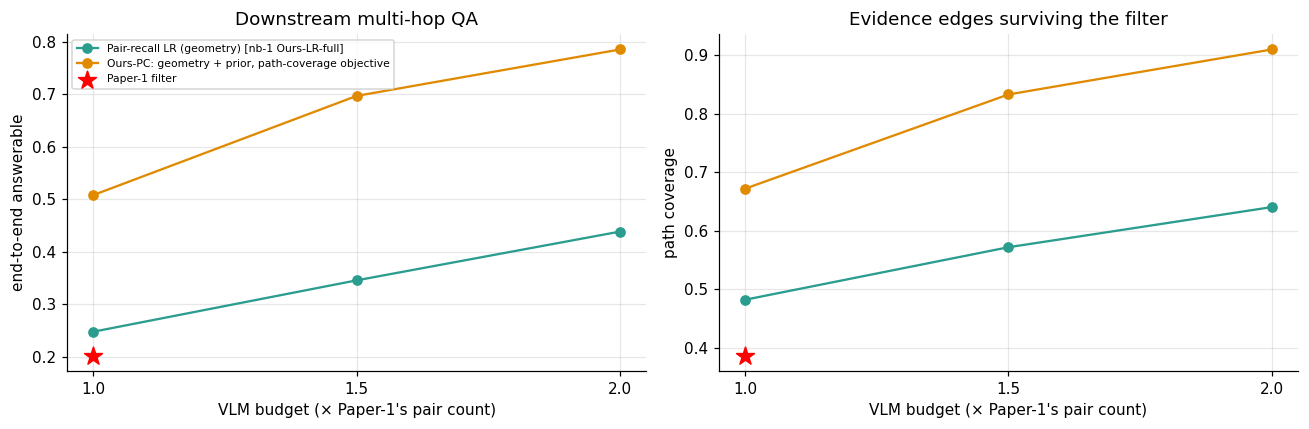

In [14]:
T_F2 = RES_F[RES_F.method.isin([order_F[1], order_F[4]])].pivot_table(index="method", columns="budget", values=["answerable", "path_coverage"], aggfunc="mean")
paper_row = T_F1.loc[order_F[0]]
print(f"Paper-1 at its own budget: answerable {paper_row.answerable:.3f}, path coverage {paper_row.path_coverage:.3f}\n")
print(T_F2.round(3).to_string()); T_F2.to_csv(f"{OUT}/tableF2_budget_sweep.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, c in [(order_F[1], C_ALT), (order_F[4], C_OURS)]:
    d_ = RES_F[RES_F.method == m].groupby("budget")[["answerable", "path_coverage"]].mean()
    ax[0].plot([1, 1.5, 2], d_.loc[["1x", "1.5x", "2x"], "answerable"], "o-", color=c, label=m)
    ax[1].plot([1, 1.5, 2], d_.loc[["1x", "1.5x", "2x"], "path_coverage"], "o-", color=c, label=m)
for a, k in zip(ax, ["answerable", "path_coverage"]):
    a.scatter([1], [paper_row[k]], color="red", marker="*", s=150, zorder=5, label="Paper-1 filter")
    a.set_xlabel("VLM budget (× Paper-1's pair count)"); a.set_xticks([1, 1.5, 2])
ax[0].set_ylabel("end-to-end answerable"); ax[1].set_ylabel("path coverage"); ax[0].legend(fontsize=7)
ax[0].set_title("Downstream multi-hop QA"); ax[1].set_title("Evidence edges surviving the filter")
plt.tight_layout(); plt.savefig(f"{OUT}/figF_path_coverage.png", bbox_inches="tight"); plt.show()

In [15]:
cat_rows = []
for sid in scans_geo:
    g = PAIRS[PAIRS.scan == sid].reset_index(drop=True); n = int(paper_filter(g).sum())
    for name, col in [(order_F[0], None), (order_F[1], "F::" + list(MODELS)[0]), (order_F[4], "F::" + list(MODELS)[3])]:
        m = paper_filter(g) if col is None else at_budget(g, g[col].values, n)
        for cat, yc in [("support/contact", "y_support"), ("proximity", "y_proximity"), ("directional", "y_directional")]:
            cat_rows.append(dict(method=name, category=cat, tp=int((m & (g[yc].values == 1)).sum()), pos=int(g[yc].sum())))
T_F3 = pd.DataFrame(cat_rows).groupby(["category", "method"])[["tp", "pos"]].sum()
T_F3 = (T_F3.tp / T_F3.pos).unstack()[[order_F[0], order_F[1], order_F[4]]]
print(T_F3.round(3).to_string()); T_F3.to_csv(f"{OUT}/tableF3_category_recall.csv")

method           Paper-1 filter (IoU OR d<0.5)  Pair-recall LR (geometry) [nb-1 Ours-LR-full]  Ours-PC: geometry + prior, path-coverage objective
category                                                                                                                                         
directional                              0.216                                          0.380                                               0.636
proximity                                0.884                                          0.769                                               0.826
support/contact                          0.973                                          0.878                                               0.395


In [16]:
# ---------------- configuration ----------------
MODEL_PREFERENCE = "7b-instruct"     # or "3b-instruct" / "1.5b-instruct" if you attached a smaller variation
N_LLM_Q          = 500
BATCH_SIZE       = 8                 # lowered automatically on out-of-memory
MAX_NEW_TOKENS   = 32
CONDITIONS       = ["LLM only (no context)", "Paper-1 chunks (k=3)", "Paper-1 chunks (k=10)",
                    "Triple-RAG (K=50)", "Ours (full)", "Gold evidence (oracle)"]
MOCK_LLM         = os.environ.get("FYDP_MOCK_LLM") == "1"   # local smoke test only
GEN_CSV          = f"{OUT}/llm_generations.csv"
# -----------------------------------------------

rng_g = np.random.default_rng(SEED + 55)
pool = [x for x in QA if x["split"] == "test"]
quota = {"quantity": 60, "attribute": 40, "1-hop": 100, "2-hop": 150, "3-hop": 150}
scale = N_LLM_Q / sum(quota.values())
LLM_Q = []
for t, k in quota.items():
    k = int(round(k * scale))
    if t in ("quantity", "attribute"):
        c = [x for x in pool if x["type"] == t]; LLM_Q += [c[i] for i in rng_g.permutation(len(c))[:k]]
    else:
        for phr in ("canonical", "paraphrased"):
            c = [x for x in pool if x["type"] == t and x["phr"] == phr]; LLM_Q += [c[i] for i in rng_g.permutation(len(c))[:k // 2]]
for n_, x in enumerate(LLM_Q): x["qid"] = f"q{n_:04d}"
print(f"LLM evaluation set: {len(LLM_Q)} questions from {len({x['scan'] for x in LLM_Q})} unseen scans")
print(Counter(x["type"] for x in LLM_Q))

LLM evaluation set: 500 questions from 78 unseen scans
Counter({'2-hop': 150, '3-hop': 150, '1-hop': 100, 'quantity': 60, 'attribute': 40})


In [17]:
# ---------------- contexts for every condition ----------------
def fact_line(kb, f):
    if f[0] == "N":
        i = f[1]; at = attr_text(kb.attrs[i]); return f"{kb.lab[i]}#{i}" + (f" ({at})" if at else "")
    _, a, p, b = f; return f"{kb.lab[a]}#{a} is {SURF[p]} {kb.lab[b]}#{b}"

def context_for(cond, x):
    kb = KB[x["scan"]]
    if cond == "LLM only (no context)": return None, []
    if cond.startswith("Paper-1"):
        k = 3 if "k=3" in cond else 10
        idx = cos_top(kb.chunk_mat, ENC.transform([x["q"]]), k); blocks, facts = [], []
        for i in idx:
            l, fs = kb.chunks[i]
            blocks.append(f"[{l}: {len(kb.by_label[l])} instance(s)]\n" + "\n".join("- " + fact_line(kb, f) for f in fs)); facts += fs
        return "\n".join(blocks), facts
    if cond.startswith("Triple"): facts = retrieve_triple(kb, x["q"], k=50)
    elif cond.startswith("Ours"): facts = retrieve_ours(kb, x["q"], **BEST)
    else:
        anchor = [("N", i) for i in kb.by_label.get(x["label"], [])]
        facts = anchor + list(x["gold_facts"]) if x["type"] not in ("quantity", "attribute") else list(x["gold_facts"])
    facts = list(dict.fromkeys(facts))
    return "\n".join("- " + fact_line(kb, f) for f in facts), facts

SYSTEM = ("You answer questions about one indoor 3D scene. Facts are written as 'object#id is <relation> object#id'; "
          "the number after # only distinguishes instances. Use only the listed facts. "
          "Reply with the answer only: object category name(s) separated by commas, no ids and no explanation. "
          "For 'how many' questions reply with one number. For colour questions reply with the colour(s). "
          "If the facts are not enough, give your single best guess.")
SYSTEM_NOCTX = ("You answer questions about a typical indoor room. Reply with the answer only: object category name(s) "
                "separated by commas, a single number for 'how many' questions, or colour(s) for colour questions. No explanation.")

JOBS = []
for cond in CONDITIONS:
    for x in LLM_Q:
        ctx, facts = context_for(cond, x)
        user = x["q"] if ctx is None else f"Scene facts:\n{ctx}\n\nQuestion: {x['q']}"
        JOBS.append(dict(key=f"{cond}|{x['qid']}", cond=cond, qid=x["qid"], system=SYSTEM if ctx else SYSTEM_NOCTX, user=user,
                         ctx_facts=len(set(facts)), ceiling=int(answer_from(KB[x["scan"]], x, facts)) if facts else 0))
print(f"{len(JOBS)} generations to run ({len(CONDITIONS)} conditions x {len(LLM_Q)} questions)")
print("\nexample prompt (Ours):\n" + next(j for j in JOBS if j["cond"] == "Ours (full)")["user"][:600])

3000 generations to run (6 conditions x 500 questions)

example prompt (Ours):
Scene facts:
- sink#11 (color: white; size: narrow, wide)

Question: how many sink are there in the room?


In [18]:
# ---------------- load the model from Kaggle's model library ----------------
def find_model_dir(pref):
    cands = []
    for root in ["/kaggle/input"]:
        if not os.path.isdir(root): continue
        for dp, dn, fn in os.walk(root):
            if "config.json" in fn and ("tokenizer.json" in fn or "tokenizer_config.json" in fn) and "qwen" in dp.lower():
                cands.append(dp)
    cands.sort(key=lambda p: (pref.replace("-", "") not in p.lower().replace("-", "").replace("_", ""), len(p)))
    return cands

tok = model = None
if MOCK_LLM:
    print("MOCK_LLM=1 -> using a rule-based stand-in reader (for testing the pipeline only; numbers are NOT LLM results)")
else:
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    assert torch.cuda.is_available(), "No GPU: set Settings -> Accelerator -> GPU T4 x2"
    cands = find_model_dir(MODEL_PREFERENCE)
    MODEL_DIR = cands[0] if cands else "Qwen/Qwen2.5-7B-Instruct"     # hub fallback needs Internet ON
    print("GPUs:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
    print("model:", MODEL_DIR)
    tok = AutoTokenizer.from_pretrained(MODEL_DIR, padding_side="left")
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(MODEL_DIR, torch_dtype=torch.float16, device_map="auto")
    model.eval()
    print("loaded in fp16 across", torch.cuda.device_count(), "GPU(s)")

GPUs: ['Tesla T4', 'Tesla T4']
model: Qwen/Qwen2.5-7B-Instruct


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

loaded in fp16 across 2 GPU(s)


In [19]:
# ---------------- generation (resumable) ----------------
def mock_generate(job):
    """Stand-in reader for local testing: executes the question over the listed facts."""
    x = next(q for q in LLM_Q if q["qid"] == job["qid"]); kb = KB[x["scan"]]
    ctx, facts = context_for(job["cond"], x)
    if not facts: return "chair"
    if x["type"] == "quantity": return str(sum(1 for f in set(facts) if f[0] == "N" and kb.lab[f[1]] == x["label"]) or 1)
    if x["type"] == "attribute":
        n = [f for f in facts if f[0] == "N" and kb.lab[f[1]] == x["label"]]; return ", ".join(kb.attrs[n[0][1]].get("color", [])) if n else "white"
    inE = defaultdict(list)
    for f in facts:
        if f[0] == "E": inE[f[3]].append((f[1], f[2]))
    F = {i for f in facts for i in ([f[1]] if f[0] == "N" else [f[1], f[3]]) if kb.lab.get(i) == x["label"]}
    for ptxt in reversed(decompose(x["q"])[2]):
        sim = pred_sims(ptxt); best = max(sim, key=sim.get); F = {u for v in F for u, p in inE[v] if p == best}
    return ", ".join(sorted({kb.lab[i] for i in F})) or "none"

done = {}
if os.path.exists(GEN_CSV):
    prev = pd.read_csv(GEN_CSV, keep_default_na=False); done = dict(zip(prev.key, prev.output))
    print(f"resuming: {len(done)} generations already saved")
todo = [j for j in JOBS if j["key"] not in done]
todo.sort(key=lambda j: len(j["user"]))                                 # similar lengths per batch -> less padding
t0 = time.time(); bs = BATCH_SIZE; k = 0; nb_ = 0
while k < len(todo):
    batch = todo[k:k+bs]
    if MOCK_LLM:
        outs = [mock_generate(j) for j in batch]
    else:
        texts = [tok.apply_chat_template([{"role": "system", "content": j["system"]}, {"role": "user", "content": j["user"]}],
                                         tokenize=False, add_generation_prompt=True) for j in batch]
        try:
            enc = tok(texts, return_tensors="pt", padding=True).to(model.device)
            with torch.no_grad():
                gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None, top_p=None,
                                     top_k=None, pad_token_id=tok.pad_token_id)
            outs = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); bs = max(1, bs // 2); print("OOM -> batch size", bs); continue
    for j, o in zip(batch, outs): done[j["key"]] = o.strip().split("\n")[0]
    k += len(batch); nb_ += 1
    if nb_ % 10 == 0 or k >= len(todo):
        pd.DataFrame({"key": list(done), "output": list(done.values())}).to_csv(GEN_CSV, index=False)
        rate = k / max(time.time() - t0, 1e-9)
        print(f"  {k}/{len(todo)} done | {rate:.2f} gen/s | ETA {(len(todo)-k)/max(rate,1e-9)/60:.1f} min")
pd.DataFrame({"key": list(done), "output": list(done.values())}).to_csv(GEN_CSV, index=False)
print(f"generation finished in {(time.time()-t0)/60:.1f} min")

  80/3000 done | 9.93 gen/s | ETA 4.9 min
  160/3000 done | 11.66 gen/s | ETA 4.1 min
  240/3000 done | 11.88 gen/s | ETA 3.9 min
  320/3000 done | 11.97 gen/s | ETA 3.7 min
  400/3000 done | 11.27 gen/s | ETA 3.8 min
  480/3000 done | 10.78 gen/s | ETA 3.9 min
  560/3000 done | 10.42 gen/s | ETA 3.9 min
  640/3000 done | 10.16 gen/s | ETA 3.9 min
  720/3000 done | 9.84 gen/s | ETA 3.9 min
  800/3000 done | 9.40 gen/s | ETA 3.9 min
  880/3000 done | 8.96 gen/s | ETA 3.9 min
  960/3000 done | 8.60 gen/s | ETA 4.0 min
  1040/3000 done | 8.15 gen/s | ETA 4.0 min
  1120/3000 done | 7.68 gen/s | ETA 4.1 min
  1200/3000 done | 7.39 gen/s | ETA 4.1 min
  1280/3000 done | 7.08 gen/s | ETA 4.0 min
  1360/3000 done | 6.76 gen/s | ETA 4.0 min
  1440/3000 done | 6.36 gen/s | ETA 4.1 min
  1520/3000 done | 5.96 gen/s | ETA 4.1 min
  1600/3000 done | 5.55 gen/s | ETA 4.2 min
  1680/3000 done | 5.16 gen/s | ETA 4.3 min
  1760/3000 done | 4.78 gen/s | ETA 4.3 min
  1840/3000 done | 4.41 gen/s | ETA 4.

In [20]:
# ---------------- scoring ----------------
def norm(s):
    s = re.sub(r"#\d+", "", s.lower()); s = re.sub(r"[^a-z0-9 ,/]", " ", s)
    s = re.sub(r"\b(the|a|an|and|or)\b", ",", s)
    return [w for w in (re.sub(r"\s+", " ", t).strip() for t in s.split(",")) if w]
def canon(w): return w[:-1] if len(w) > 3 and w.endswith("s") and not w.endswith("ss") else w

def score(x, out):
    if x["type"] == "quantity":
        m = re.search(r"\d+", out); words = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "zero": 0, "none": 0}
        v = int(m.group()) if m else next((n for w, n in words.items() if w in out.lower()), -1)
        return float(v == x["gold"]), float(v == x["gold"])
    gold = {canon(g) for g in x["gold"]}; pred = {canon(w) for w in norm(out)}
    if x["type"] == "attribute":
        hit = float(bool(pred & gold) or any(g in out.lower() for g in gold)); return hit, hit
    tp = len(pred & gold); p = tp / max(len(pred), 1); r = tp / max(len(gold), 1)
    return float(pred == gold), (2*p*r / (p + r) if p + r else 0.0)

QX = {x["qid"]: x for x in LLM_Q}; rows = []
for j in JOBS:
    x = QX[j["qid"]]; out = done.get(j["key"], ""); em, f1 = score(x, out)
    rows.append(dict(condition=j["cond"], qid=j["qid"], scan=x["scan"], type=x["type"], phr=x["phr"], question=x["q"],
                     gold=", ".join(sorted(map(str, x["gold"]))) if not isinstance(x["gold"], int) else str(x["gold"]),
                     output=out, exact=em, f1=f1, ceiling=j["ceiling"], ctx_facts=j["ctx_facts"],
                     tokens=len(tok(j["user"])["input_ids"]) if tok is not None else int(1.3 * len(j["user"].split()))))
RES_G = pd.DataFrame(rows); RES_G.to_csv(f"{OUT}/tableG_llm_all_answers.csv", index=False)

T_G1 = RES_G.groupby("condition").agg(accuracy=("exact", "mean"), set_f1=("f1", "mean"), context_ceiling=("ceiling", "mean"),
                                      prompt_tokens=("tokens", "mean")).reindex(CONDITIONS)
T_G1["reader_loss (ceiling - accuracy)"] = T_G1.context_ceiling - T_G1.accuracy
print(("MOCK READER - NOT LLM RESULTS\n" if MOCK_LLM else "") + "Real LLM accuracy on 500 unseen-scan questions:\n")
print(T_G1.round(3).to_string()); T_G1.to_csv(f"{OUT}/tableG1_llm_accuracy.csv")
T_G2 = RES_G.pivot_table(index="condition", columns="type", values="exact", aggfunc="mean").reindex(CONDITIONS)[["quantity", "attribute", "1-hop", "2-hop", "3-hop"]]
print("\nAccuracy by question type:"); print(T_G2.round(3).to_string()); T_G2.to_csv(f"{OUT}/tableG2_llm_by_type.csv")
T_G3 = RES_G[RES_G.type.str.contains("hop")].pivot_table(index="condition", columns="phr", values="exact", aggfunc="mean").reindex(CONDITIONS)
print("\nRelational questions by wording:"); print(T_G3.round(3).to_string()); T_G3.to_csv(f"{OUT}/tableG3_llm_by_wording.csv")

Real LLM accuracy on 500 unseen-scan questions:

                        accuracy  set_f1  context_ceiling  prompt_tokens  reader_loss (ceiling - accuracy)
condition                                                                                                 
LLM only (no context)      0.110   0.136            0.000         14.926                            -0.110
Paper-1 chunks (k=3)       0.468   0.656            0.824        767.682                             0.356
Paper-1 chunks (k=10)      0.452   0.631            0.994       2445.856                             0.542
Triple-RAG (K=50)          0.434   0.623            0.798        671.352                             0.364
Ours (full)                0.560   0.733            0.958        169.162                             0.398
Gold evidence (oracle)     0.600   0.774            1.000         94.892                             0.400

Accuracy by question type:
type                    quantity  attribute  1-hop  2-hop  3-hop
co

             baseline  delta_accuracy  ci95_low  ci95_high  p_one_sided
LLM only (no context)           0.450     0.416      0.531          0.0
 Paper-1 chunks (k=3)           0.092     0.048      0.129          0.0
Paper-1 chunks (k=10)           0.108     0.058      0.149          0.0
    Triple-RAG (K=50)           0.126     0.083      0.165          0.0


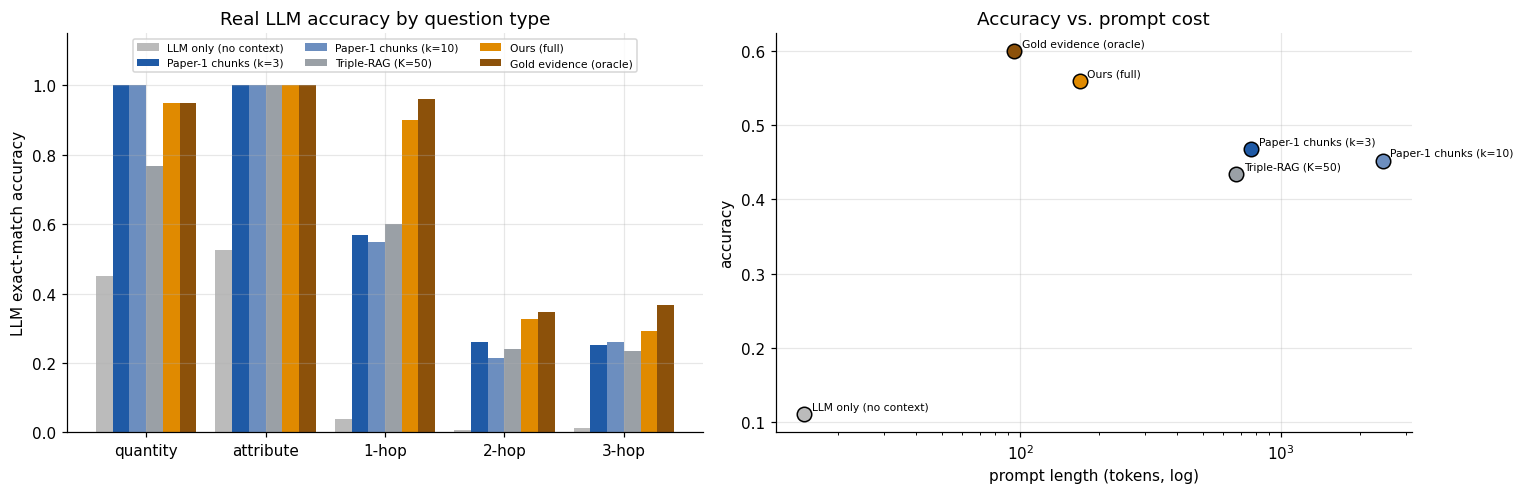


example answers (Ours vs Paper-1 k=3, 3-hop):
Q: what is to the left of the object that is to the right of the object that is to the left of the door?
   gold: chair, dining table | Paper-1 k=3: dining table | Ours: dining table
Q: what is behind the object that is to the right of the object that is close to the table?
   gold: organizer | Paper-1 k=3: organizer | Ours: wardrobe
Q: what is close to the object that is behind the object that is in front of the cutting board?
   gold: item | Paper-1 k=3: stove | Ours: kitchen appliance
Q: what is to the left of the object that is to the right of the object that is behind the doorframe?
   gold: doorframe, radiator, toilet | Paper-1 k=3: toilet | Ours: radiator
Q: what is in front of the object that is in front of the object that is close to the cabinet?
   gold: chair, table | Paper-1 k=3: sofa | Ours: chair


In [21]:
# ---------------- significance (paired bootstrap over scans) + figure ----------------
def boot(a, b, n=2000):
    A = RES_G[RES_G.condition == a].set_index("qid").exact; B = RES_G[RES_G.condition == b].set_index("qid").exact
    df = pd.DataFrame({"d": B - A.reindex(B.index), "scan": RES_G[RES_G.condition == b].set_index("qid").scan})
    per = df.groupby("scan").d.mean().values
    bs = np.array([per[np.random.default_rng(i).integers(0, len(per), len(per))].mean() for i in range(n)])
    return (B - A.reindex(B.index)).mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), (bs <= 0).mean()
sigG = []
for base in [c for c in CONDITIONS if c not in ("Ours (full)", "Gold evidence (oracle)")]:
    m, lo, hi, p = boot(base, "Ours (full)"); sigG.append(dict(baseline=base, delta_accuracy=m, ci95_low=lo, ci95_high=hi, p_one_sided=p))
T_G4 = pd.DataFrame(sigG); print(T_G4.round(3).to_string(index=False)); T_G4.to_csv(f"{OUT}/tableG4_llm_significance.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
palette = {"LLM only (no context)": "#bbbbbb", "Paper-1 chunks (k=3)": C_PAPER, "Paper-1 chunks (k=10)": "#6c8ebf",
           "Triple-RAG (K=50)": C_GREY, "Ours (full)": C_OURS, "Gold evidence (oracle)": "#8c510a"}
colsG = [palette[c] for c in CONDITIONS]
xk = np.arange(5); w = 0.14
for i, (c, col) in enumerate(zip(CONDITIONS, colsG)):
    ax[0].bar(xk + (i-(len(CONDITIONS)-1)/2)*w, T_G2.loc[c].values, w, color=col, label=c)
ax[0].set_xticks(xk); ax[0].set_xticklabels(T_G2.columns); ax[0].set_ylim(0, 1.15); ax[0].set_ylabel("LLM exact-match accuracy")
ax[0].set_title("Real LLM accuracy by question type"); ax[0].legend(fontsize=7, ncol=3, loc="upper center")
for c, col in zip(CONDITIONS, colsG):
    r = T_G1.loc[c]; ax[1].scatter(r.prompt_tokens, r.accuracy, s=90, color=col, edgecolor="k", zorder=3)
    ax[1].annotate(c, (r.prompt_tokens, r.accuracy), fontsize=7, xytext=(5, 3), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("prompt length (tokens, log)"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Accuracy vs. prompt cost")
plt.tight_layout(); plt.savefig(f"{OUT}/figG_llm_reader.png", bbox_inches="tight"); plt.show()

print("\nexample answers (Ours vs Paper-1 k=3, 3-hop):")
ex = RES_G[(RES_G.type == "3-hop")].pivot_table(index=["qid", "question", "gold"], columns="condition", values="output", aggfunc="first").reset_index()
for _, r in ex.head(5).iterrows():
    print(f"Q: {r.question}\n   gold: {r.gold} | Paper-1 k=3: {r['Paper-1 chunks (k=3)']} | Ours: {r['Ours (full)']}")